In [1]:
import sys
import torch
import torchvision
import numpy as np
import rasterio
import yaml
import json
import hashlib

from pathlib import Path

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Rasterio:", rasterio.__version__)
print("CUDA:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Inference device:", device)

print("\nEnvironment ready!")

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Interpreter: d:\FloodVision-AI\ml\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
NumPy: 2.5.4
Rasterio: 1.5.2
CUDA: False
Inference device: cpu

Environment ready!


In [2]:
ML_DIR = Path(r"D:\FloodVision-AI\ml")

SRC_DIR = ML_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

PRODUCTION_DIR = (
    ML_DIR / "artifacts" / "production"
)

MODEL_PATH = (
    PRODUCTION_DIR /
    "floodvision_mobilenetv3_v1.pt"
)

assert ML_DIR.is_dir()
assert SRC_DIR.is_dir()
assert PRODUCTION_DIR.is_dir()
assert MODEL_PATH.is_file()

print("ML directory:", ML_DIR)
print("Production directory:", PRODUCTION_DIR)
print("Model exists:", MODEL_PATH.exists())

print(
    "Model size:",
    round(MODEL_PATH.stat().st_size / 1024**2, 2),
    "MiB"
)

print("\nAll production paths verified!")

ML directory: D:\FloodVision-AI\ml
Production directory: D:\FloodVision-AI\ml\artifacts\production
Model exists: True
Model size: 4.13 MiB

All production paths verified!


In [3]:
artifact = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

print("Artifact type:", type(artifact))

if isinstance(artifact, dict):

    print("\nArtifact keys:")

    for key, value in artifact.items():
        print(f"{key}: {type(value).__name__}")

print("\nProduction artifact loaded!")

Artifact type: <class 'dict'>

Artifact keys:
format_version: int
model_version: str
model_config: dict
model_state_dict: OrderedDict
inference_config: dict
source_experiment: str
checkpoint_epoch: int
validation_iou: float

Production artifact loaded!


In [4]:
from pprint import pprint

print("Format version:", artifact["format_version"])
print("Model version:", artifact["model_version"])

print("\nModel configuration:")
pprint(artifact["model_config"])

print("\nInference configuration:")
pprint(artifact["inference_config"])

print("\nSource experiment:", artifact["source_experiment"])
print("Checkpoint epoch:", artifact["checkpoint_epoch"])
print("Validation IoU:", artifact["validation_iou"])

Format version: 1
Model version: 1.0.0

Model configuration:
{'in_channels': 2,
 'name': 'mobilenet_unet',
 'out_channels': 1,
 'pretrained': False}

Inference configuration:
{'ignore_index': -1,
 'input_bands': ['VV', 'VH'],
 'input_channels': 2,
 'output_type': 'logits',
 'task': 'binary_water_segmentation',
 'threshold': 0.5,
 'tile_height': 512,
 'tile_width': 512}

Source experiment: EXP007
Checkpoint epoch: 18
Validation IoU: 0.834588667782897


In [5]:
from floodvision.inference.model_loader import ModelLoader

loader = ModelLoader(
    bundle_dir=PRODUCTION_DIR
)

verification = loader.verify_integrity()

print("=" * 55)
print("PRODUCTION BUNDLE INTEGRITY")
print("=" * 55)

print("Status:", verification["status"])
print("Version:", verification["bundle_version"])

for filename in verification["verified_files"]:
    print(f"[PASS] {filename}")

print(
    "\nVerified files:",
    verification["total_files"]
)

assert verification["status"] == "verified"
assert verification["total_files"] == 4

print("\nIntegrity verification PASSED!")

PRODUCTION BUNDLE INTEGRITY
Status: verified
Version: 1.0.0
[PASS] floodvision_mobilenetv3_v1.pt
[PASS] preprocessing.yaml
[PASS] metadata.json
[PASS] MODEL_CARD.md

Verified files: 4

Integrity verification PASSED!


In [6]:
import importlib

import floodvision.inference.model_loader as loader_module

importlib.reload(loader_module)

ModelLoader = loader_module.ModelLoader

loader = ModelLoader(
    bundle_dir=PRODUCTION_DIR
)

print("Updated ModelLoader imported!")
print("Model loaded:", loader.is_loaded)

Updated ModelLoader imported!
Model loaded: False


In [7]:
model = loader.load(device="auto")

info = loader.get_model_info()

print("=" * 55)
print("PRODUCTION MODEL INFORMATION")
print("=" * 55)

for key, value in info.items():
    print(f"{key}: {value}")

assert loader.is_loaded
assert info["parameters"] == 1034057
assert info["trainable_parameters"] == 0
assert info["training_mode"] is False
assert info["status"] == "ready"

print("\nProduction model loading PASSED!")

PRODUCTION MODEL INFORMATION
model_name: MobileNetV3 U-Net
model_version: 1.0.0
device: cpu
parameters: 1034057
trainable_parameters: 0
training_mode: False
threshold: 0.5
input_bands: ['VV', 'VH']
tile_height: 512
tile_width: 512
status: ready

Production model loading PASSED!


In [8]:
import time

start = time.perf_counter()

cached_model = loader.load(device="auto")

elapsed = (
    time.perf_counter() - start
) * 1000

assert model is cached_model

print("Original model ID:", id(model))
print("Cached model ID:", id(cached_model))

print(
    "Same model instance:",
    model is cached_model
)

print(f"Cache retrieval time: {elapsed:.4f} ms")

print("\nModel caching PASSED!")

Original model ID: 3023870295888
Cached model ID: 3023870295888
Same model instance: True
Cache retrieval time: 0.0980 ms

Model caching PASSED!


In [9]:
import torch

torch.manual_seed(42)

test_input = torch.randn(
    1, 2, 512, 512,
    device=loader.device
)

with torch.inference_mode():

    logits = model(test_input)

    probabilities = torch.sigmoid(logits)

    prediction = (
        probabilities >= loader.inference_config["threshold"]
    ).to(torch.uint8)

print("=" * 55)
print("PRODUCTION INFERENCE SMOKE TEST")
print("=" * 55)

print("Input shape:", test_input.shape)
print("Logits shape:", logits.shape)
print("Probability shape:", probabilities.shape)
print("Prediction shape:", prediction.shape)

print(
    "Minimum probability:",
    probabilities.min().item()
)

print(
    "Maximum probability:",
    probabilities.max().item()
)

print(
    "Prediction labels:",
    torch.unique(prediction)
)

assert logits.shape == (1, 1, 512, 512)
assert torch.isfinite(logits).all()
assert probabilities.min().item() >= 0
assert probabilities.max().item() <= 1
assert not logits.requires_grad

print("\nProduction inference smoke test PASSED!")

PRODUCTION INFERENCE SMOKE TEST
Input shape: torch.Size([1, 2, 512, 512])
Logits shape: torch.Size([1, 1, 512, 512])
Probability shape: torch.Size([1, 1, 512, 512])
Prediction shape: torch.Size([1, 1, 512, 512])
Minimum probability: 0.00021767763246316463
Maximum probability: 0.977687418460846
Prediction labels: tensor([0, 1], dtype=torch.uint8)

Production inference smoke test PASSED!


In [10]:
import shutil
import tempfile

from pathlib import Path

from floodvision.inference.exceptions import (
    ArtifactIntegrityError
)

with tempfile.TemporaryDirectory() as temp_dir:

    test_bundle = Path(temp_dir) / "production"

    shutil.copytree(
        PRODUCTION_DIR,
        test_bundle
    )

    corrupted_path = (
        test_bundle /
        "floodvision_mobilenetv3_v1.pt"
    )

    # Modify one byte without changing file size.
    with open(corrupted_path, "r+b") as file:

        file.seek(100)

        original_byte = file.read(1)

        file.seek(100)

        file.write(
            bytes([original_byte[0] ^ 0xFF])
        )

    corrupted_loader = ModelLoader(
        bundle_dir=test_bundle
    )

    try:

        corrupted_loader.load(device="cpu")

    except ArtifactIntegrityError as exc:

        print("[PASS] Corrupted artifact rejected")
        print("Reason:", exc)

    else:

        raise AssertionError(
            "Corrupted artifact was not rejected!"
        )

print("\nCorruption rejection test PASSED!")

[PASS] Corrupted artifact rejected
Reason: SHA-256 mismatch: floodvision_mobilenetv3_v1.pt

Corruption rejection test PASSED!


In [11]:
from floodvision.inference.exceptions import (
    ArtifactNotFoundError
)

with tempfile.TemporaryDirectory() as temp_dir:

    test_bundle = Path(temp_dir) / "production"

    shutil.copytree(
        PRODUCTION_DIR,
        test_bundle
    )

    missing_file = (
        test_bundle / "metadata.json"
    )

    missing_file.unlink()

    missing_loader = ModelLoader(
        bundle_dir=test_bundle
    )

    try:

        missing_loader.load(device="cpu")

    except ArtifactNotFoundError as exc:

        print("[PASS] Missing artifact detected")
        print("Reason:", exc)

    else:

        raise AssertionError(
            "Missing artifact was not detected!"
        )

print("\nMissing artifact test PASSED!")

[PASS] Missing artifact detected
Reason: Missing artifact: metadata.json

Missing artifact test PASSED!


In [12]:
from floodvision.inference.exceptions import (
    ModelCompatibilityError
)

invalid_artifact = artifact.copy()

invalid_artifact["model_version"] = "99.0.0"

try:

    loader.validate_artifact(
        invalid_artifact
    )

except ModelCompatibilityError as exc:

    print("[PASS] Unsupported version rejected")
    print("Reason:", exc)

else:

    raise AssertionError(
        "Unsupported version was accepted!"
    )

print("\nVersion compatibility test PASSED!")

[PASS] Unsupported version rejected
Reason: Unsupported model version.

Version compatibility test PASSED!


In [13]:
from floodvision.inference.exceptions import (
    DeviceUnavailableError
)

try:

    loader.resolve_device("invalid_device")

except DeviceUnavailableError as exc:

    print("[PASS] Invalid device rejected")
    print("Reason:", exc)

else:

    raise AssertionError(
        "Invalid device was accepted!"
    )

print("\nDevice validation test PASSED!")

[PASS] Invalid device rejected
Reason: Invalid device: invalid_device

Device validation test PASSED!


In [14]:
verification = loader.verify_integrity()

assert verification["status"] == "verified"
assert verification["total_files"] == 4

assert loader.is_loaded
assert loader.model is model

print("Original production bundle: SAFE")
print("Original model instance: UNCHANGED")
print("Integrity verification: PASSED")

print("\nAll model loader checks completed!")

Original production bundle: SAFE
Original model instance: UNCHANGED
Integrity verification: PASSED

All model loader checks completed!


In [15]:
from floodvision.inference.preprocessor import (
    SARPreprocessor
)

preprocessor = SARPreprocessor(
    config_path=PRODUCTION_DIR / "preprocessing.yaml",
    require_crs=True,
    allow_unverified_band_order=True
)

print("Production preprocessor initialized!")

print(
    "Normalization method:",
    preprocessor.config["method"]
)

print(
    "Band names:",
    preprocessor.normalizer.band_names
)

print(
    "Invalid fill value:",
    preprocessor.config["invalid_fill_value"]
)

print(
    "Ignore index:",
    preprocessor.config["ignore_index"]
)

Production preprocessor initialized!
Normalization method: percentile_zscore
Band names: ['VV', 'VH']
Invalid fill value: 0.0
Ignore index: -1


In [16]:
import pandas as pd
import yaml

dataset_config_path = (
    ML_DIR / "configs" / "dataset.yaml"
)

with open(
    dataset_config_path,
    "r",
    encoding="utf-8"
) as file:

    dataset_config = yaml.safe_load(file)["dataset"]

val_split_path = (
    ML_DIR /
    "data/splits/geographical/val.csv"
)

val_samples = pd.read_csv(val_split_path)

sample_id = val_samples.iloc[0]["sample_id"]

image_dir = (
    ML_DIR
    / dataset_config["root_dir"]
    / dataset_config["image_dir"]
)

sample_path = (
    image_dir / f"{sample_id}_S1Hand.tif"
)

assert sample_path.is_file(), (
    f"Satellite image missing: {sample_path}"
)

print("Sample ID:", sample_id)
print("Image path:", sample_path)
print("Image exists:", sample_path.exists())

Sample ID: Mekong_1111068
Image path: D:\FloodVision-AI\ml\data\raw\Sen1Floods11\S1Hand\Mekong_1111068_S1Hand.tif
Image exists: True


In [17]:
metadata = preprocessor.validator.validate_raster(
    sample_path
)

print("=" * 55)
print("SATELLITE RASTER METADATA")
print("=" * 55)

print("Width:", metadata.width)
print("Height:", metadata.height)
print("Channels:", metadata.count)
print("CRS:", metadata.crs)
print("Transform:", metadata.transform)
print("Data types:", metadata.dtypes)
print("NoData values:", metadata.nodata_values)
print("Band descriptions:", metadata.band_descriptions)

print(
    "Band order verified:",
    metadata.band_order_verified
)

print("\nRaster validation PASSED!")

SATELLITE RASTER METADATA
Width: 512
Height: 512
Channels: 2
CRS: EPSG:4326
Transform: | 0.00, 0.00, 105.83|
| 0.00,-0.00, 12.05|
| 0.00, 0.00, 1.00|
Data types: ('float32', 'float32')
NoData values: (nan, nan)
Band descriptions: ('VV', 'VH')
Band order verified: True

Raster validation PASSED!


In [18]:
sar_input = preprocessor.read(sample_path)

print("=" * 55)
print("RAW SAR IMAGE")
print("=" * 55)

print("Image shape:", sar_input.image.shape)
print("Image dtype:", sar_input.image.dtype)
print("Mask shape:", sar_input.valid_mask.shape)
print("Mask dtype:", sar_input.valid_mask.dtype)

valid_pixels = int(
    sar_input.valid_mask.sum()
)

invalid_pixels = int(
    sar_input.valid_mask.size - valid_pixels
)

print("Valid pixels:", valid_pixels)
print("Invalid pixels:", invalid_pixels)

print(
    "Valid percentage:",
    round(
        valid_pixels
        / sar_input.valid_mask.size * 100,
        4
    )
)

assert sar_input.image.shape == (2, 512, 512)
assert sar_input.valid_mask.shape == (512, 512)

print("\nRaw SAR validation PASSED!")

RAW SAR IMAGE
Image shape: (2, 512, 512)
Image dtype: float32
Mask shape: (512, 512)
Mask dtype: bool
Valid pixels: 262144
Invalid pixels: 0
Valid percentage: 100.0

Raw SAR validation PASSED!


In [19]:
processed = preprocessor(sample_path)

print("=" * 55)
print("PRODUCTION PREPROCESSING")
print("=" * 55)

print("Tensor shape:", processed.tensor.shape)
print("Tensor dtype:", processed.tensor.dtype)
print("Tensor device:", processed.tensor.device)

print("Valid pixels:", processed.valid_pixels)
print("Invalid pixels:", processed.invalid_pixels)
print("Total pixels:", processed.total_pixels)

print(
    "Valid percentage:",
    round(processed.valid_percentage, 4)
)

print("Minimum:", processed.tensor.min().item())
print("Maximum:", processed.tensor.max().item())

print(
    "NaN count:",
    torch.isnan(processed.tensor).sum().item()
)

print(
    "Inf count:",
    torch.isinf(processed.tensor).sum().item()
)

assert processed.tensor.shape == (1, 2, 512, 512)
assert processed.tensor.dtype == torch.float32
assert torch.isfinite(processed.tensor).all()

assert (
    processed.valid_pixels
    + processed.invalid_pixels
    == 512 * 512
)

print("\nProduction preprocessing PASSED!")

PRODUCTION PREPROCESSING
Tensor shape: torch.Size([1, 2, 512, 512])
Tensor dtype: torch.float32
Tensor device: cpu
Valid pixels: 262144
Invalid pixels: 0
Total pixels: 262144
Valid percentage: 100.0
Minimum: -3.6094841957092285
Maximum: 2.0742764472961426
NaN count: 0
Inf count: 0

Production preprocessing PASSED!


In [20]:
from floodvision.datasets.flood_dataset import (
    FloodDataset
)

validation_dataset = FloodDataset(
    dataset_config_path=(
        ML_DIR / "configs/dataset.yaml"
    ),
    preprocessing_config_path=(
        ML_DIR / "configs/preprocessing.yaml"
    ),
    split_path=val_split_path,
    transforms=None
)

training_sample = validation_dataset[0]

assert training_sample["sample_id"] == sample_id

training_tensor = training_sample["image"]

production_tensor = processed.tensor.squeeze(0)

difference = (
    training_tensor - production_tensor
).abs()

max_difference = difference.max().item()
mean_difference = difference.mean().item()

identical = torch.equal(
    training_tensor,
    production_tensor
)

print("=" * 55)
print("TRAINING-INFERENCE EQUIVALENCE")
print("=" * 55)

print("Sample ID:", sample_id)

print(
    "Training tensor:",
    training_tensor.shape
)

print(
    "Production tensor:",
    production_tensor.shape
)

print("Maximum difference:", max_difference)
print("Mean difference:", mean_difference)
print("Exactly identical:", identical)

assert identical, (
    "Training and production preprocessing differ!"
)

print("\nPreprocessing equivalence test PASSED!")

TRAINING-INFERENCE EQUIVALENCE
Sample ID: Mekong_1111068
Training tensor: torch.Size([2, 512, 512])
Production tensor: torch.Size([2, 512, 512])
Maximum difference: 0.0
Mean difference: 0.0
Exactly identical: True

Preprocessing equivalence test PASSED!


In [21]:
with torch.inference_mode():

    logits = model(
        processed.tensor.to(loader.device)
    )

    probabilities = (
        torch.sigmoid(logits)
        .squeeze(0)
        .squeeze(0)
        .cpu()
        .numpy()
    )

prediction = (
    probabilities
    >= loader.inference_config["threshold"]
).astype(np.int8)

# Preserve invalid pixels.
prediction[~processed.valid_mask] = -1

# Invalid probabilities are undefined.
probabilities[~processed.valid_mask] = np.nan

water_pixels = int(
    (prediction == 1).sum()
)

non_water_pixels = int(
    (prediction == 0).sum()
)

invalid_pixels = int(
    (prediction == -1).sum()
)

valid_pixels = water_pixels + non_water_pixels

water_coverage = (
    water_pixels / valid_pixels
) * 100

print("=" * 55)
print("ACTUAL SATELLITE IMAGE INFERENCE")
print("=" * 55)

print("Sample ID:", sample_id)
print("Logits shape:", logits.shape)
print("Prediction shape:", prediction.shape)

print("Water pixels:", water_pixels)
print("Non-water pixels:", non_water_pixels)
print("Invalid pixels:", invalid_pixels)

print(
    f"Predicted water coverage: {water_coverage:.4f}%"
)

print(
    "Prediction labels:",
    np.unique(prediction)
)

assert prediction.shape == (512, 512)
assert np.isin(prediction, [-1, 0, 1]).all()

assert invalid_pixels == processed.invalid_pixels

assert (
    water_pixels
    + non_water_pixels
    + invalid_pixels
    == 512 * 512
)

assert np.isfinite(
    probabilities[processed.valid_mask]
).all()

print("\nActual satellite image inference PASSED!")

ACTUAL SATELLITE IMAGE INFERENCE
Sample ID: Mekong_1111068
Logits shape: torch.Size([1, 1, 512, 512])
Prediction shape: (512, 512)
Water pixels: 66106
Non-water pixels: 196038
Invalid pixels: 0
Predicted water coverage: 25.2174%
Prediction labels: [0 1]

Actual satellite image inference PASSED!


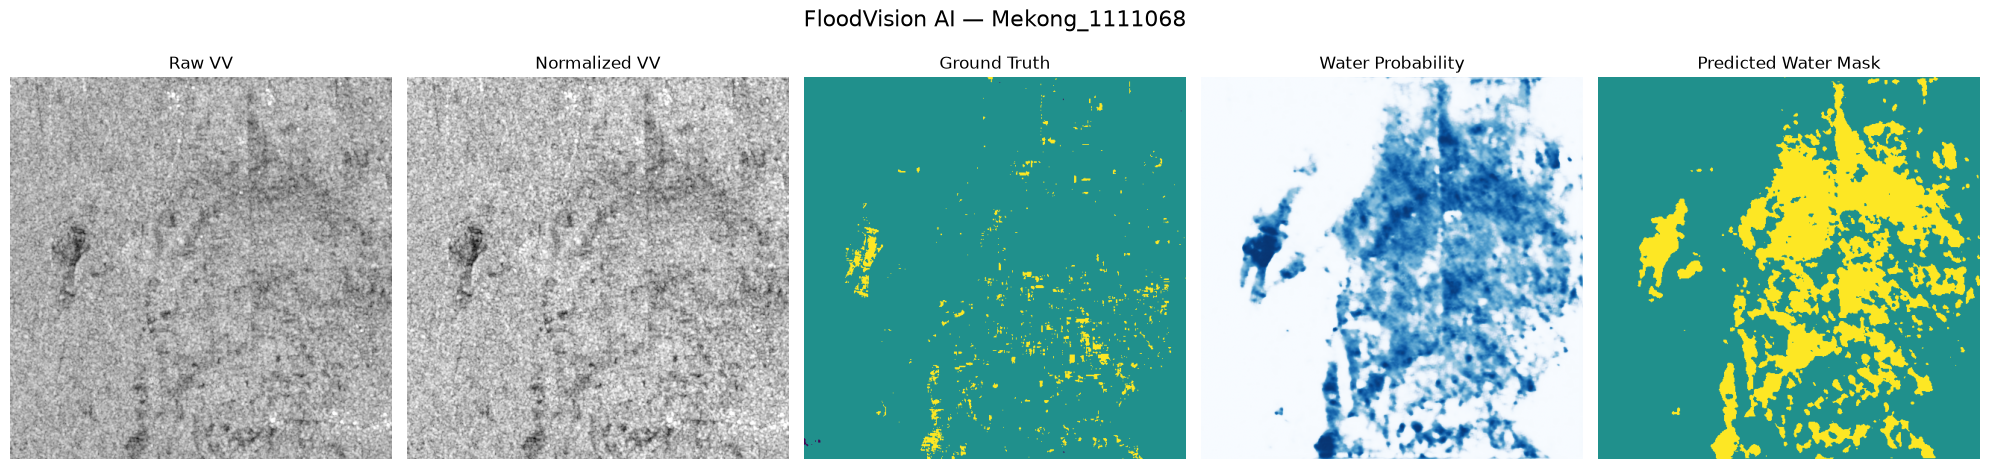

In [22]:
import matplotlib.pyplot as plt

ground_truth = (
    training_sample["mask"]
    .squeeze(0)
    .numpy()
)

fig, axes = plt.subplots(
    1, 5,
    figsize=(20, 5)
)

axes[0].imshow(
    sar_input.image[0],
    cmap="gray",
    vmin=-25,
    vmax=0
)
axes[0].set_title("Raw VV")

axes[1].imshow(
    processed.tensor[0, 0].numpy(),
    cmap="gray"
)
axes[1].set_title("Normalized VV")

axes[2].imshow(
    ground_truth,
    cmap="viridis",
    vmin=-1,
    vmax=1
)
axes[2].set_title("Ground Truth")

axes[3].imshow(
    probabilities,
    cmap="Blues",
    vmin=0,
    vmax=1
)
axes[3].set_title("Water Probability")

axes[4].imshow(
    prediction,
    cmap="viridis",
    vmin=-1,
    vmax=1
)
axes[4].set_title("Predicted Water Mask")

for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"FloodVision AI — {sample_id}",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [23]:
from floodvision.metrics.segmentation import (
    SegmentationMetrics
)

metrics = SegmentationMetrics(
    threshold=loader.inference_config["threshold"]
)

target = (
    training_sample["mask"]
    .unsqueeze(0)
    .to(logits.device)
)

metrics.update(
    logits,
    target
)

sample_metrics = metrics.compute()

print("=" * 55)
print("SINGLE SAMPLE SEGMENTATION QUALITY")
print("=" * 55)

for key, value in sample_metrics.items():
    print(f"{key}: {value:.4f}")

gt_water = int(
    (ground_truth == 1).sum()
)

gt_valid = int(
    (ground_truth != -1).sum()
)

print("\nGround truth water pixels:", gt_water)

print(
    "Ground truth water coverage:",
    round(gt_water / gt_valid * 100, 4),
    "%"
)

print(
    "Predicted water coverage:",
    round(water_coverage, 4),
    "%"
)

SINGLE SAMPLE SEGMENTATION QUALITY
accuracy: 0.7673
precision: 0.0949
recall: 0.8425
iou: 0.0933
dice: 0.1706
specificity: 0.7650

Ground truth water pixels: 7449
Ground truth water coverage: 2.8421 %
Predicted water coverage: 25.2174 %


In [24]:
from floodvision.inference.schemas import SARInput

test_image = sar_input.image.copy()
test_valid_mask = sar_input.valid_mask.copy()

# Introduce invalid pixels.
test_image[0, 0, 0] = np.nan
test_image[1, 0, 1] = np.inf
test_image[0, 0, 2] = -np.inf

# Explicitly invalid pixel.
test_valid_mask[0, 3] = False

test_sar_input = SARInput(
    image=test_image,
    valid_mask=test_valid_mask,
    metadata=sar_input.metadata
)

test_processed = preprocessor.preprocess(
    test_sar_input
)

print("Invalid pixels:", test_processed.invalid_pixels)

print(
    "Invalid pixel values:",
    test_processed.tensor[0, :, 0, :4]
)

assert test_processed.invalid_pixels == 4

assert torch.isfinite(
    test_processed.tensor
).all()

assert torch.all(
    test_processed.tensor[0, :, 0, :4] == 0
)

print("\nInvalid pixel handling PASSED!")

Invalid pixels: 4
Invalid pixel values: tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.]])

Invalid pixel handling PASSED!


In [25]:
from floodvision.inference.exceptions import (
    InputValidationError
)

validator = preprocessor.validator


def expect_rejection(name, function):

    try:
        function()

    except InputValidationError as exc:

        print(f"[PASS] {name}")
        print(f"Reason: {exc}\n")

    else:

        raise AssertionError(
            f"{name} was not rejected!"
        )


# 1. Incorrect channel count
expect_rejection(
    "Incorrect channel count",
    lambda: validator.validate_array(
        np.zeros((3, 512, 512), dtype=np.float32),
        np.ones((512, 512), dtype=bool)
    )
)


# 2. Incorrect tile dimensions
expect_rejection(
    "Incorrect tile dimensions",
    lambda: validator.validate_array(
        np.zeros((2, 256, 256), dtype=np.float32),
        np.ones((256, 256), dtype=bool)
    )
)


# 3. Invalid mask dimensions
expect_rejection(
    "Invalid mask dimensions",
    lambda: validator.validate_array(
        sar_input.image,
        np.ones((256, 256), dtype=bool)
    )
)


# 4. Invalid mask dtype
expect_rejection(
    "Invalid mask dtype",
    lambda: validator.validate_array(
        sar_input.image,
        np.ones((512, 512), dtype=np.uint8)
    )
)


# 5. Completely invalid image
expect_rejection(
    "Completely invalid image",
    lambda: validator.validate_array(
        sar_input.image,
        np.zeros((512, 512), dtype=bool)
    )
)


# 6. Reversed band order
expect_rejection(
    "Reversed band order",
    lambda: validator.validate_band_order(
        ("VH", "VV")
    )
)


# 7. Missing file
expect_rejection(
    "Missing input file",
    lambda: validator.validate_path(
        ML_DIR / "nonexistent_image.tif"
    )
)

print("All input rejection tests PASSED!")

[PASS] Incorrect channel count
Reason: Expected exactly 2 SAR channels.

[PASS] Incorrect tile dimensions
Reason: Invalid tile shape: (2, 256, 256)

[PASS] Invalid mask dimensions
Reason: Valid mask dimensions do not match image.

[PASS] Invalid mask dtype
Reason: Valid mask must have boolean dtype.

[PASS] Completely invalid image
Reason: Image contains no valid input pixels.

[PASS] Reversed band order
Reason: Incorrect band order: ('VH', 'VV'). Expected VV followed by VH.

[PASS] Missing input file
Reason: Input file not found: D:\FloodVision-AI\ml\nonexistent_image.tif

All input rejection tests PASSED!


In [26]:
strict_preprocessor = SARPreprocessor(
    config_path=PRODUCTION_DIR / "preprocessing.yaml",
    require_crs=True,
    allow_unverified_band_order=False
)

strict_processed = strict_preprocessor(
    sample_path
)

assert strict_processed.metadata.band_order_verified

assert torch.equal(
    processed.tensor,
    strict_processed.tensor
)

print("Strict band verification: PASSED")
print("Tensor equivalence: PASSED")

print("\nStrict preprocessing PASSED!")

Strict band verification: PASSED
Tensor equivalence: PASSED

Strict preprocessing PASSED!


In [27]:
from floodvision.inference.predictor import (
    FloodPredictor
)

from floodvision.inference.postprocessor import (
    SegmentationPostprocessor
)

predictor = FloodPredictor(
    loader=loader,
    device="auto"
)

postprocessor = SegmentationPostprocessor(
    threshold=loader.inference_config["threshold"]
)

assert predictor.model is loader.model

print("Predictor initialized!")
print("Postprocessor initialized!")

print("Device:", predictor.device)
print("Threshold:", postprocessor.threshold)

print(
    "Cached model reused:",
    predictor.model is loader.model
)

Predictor initialized!
Postprocessor initialized!
Device: cpu
Threshold: 0.5
Cached model reused: True


In [28]:
raw_prediction = predictor(processed)

print("=" * 55)
print("PRODUCTION RAW PREDICTION")
print("=" * 55)

print("Logits shape:", raw_prediction.logits.shape)
print("Logits dtype:", raw_prediction.logits.dtype)
print("Logits device:", raw_prediction.logits.device)

print("Model version:", raw_prediction.model_version)
print("Inference device:", raw_prediction.device)

print(
    f"Inference time: "
    f"{raw_prediction.inference_time_ms:.4f} ms"
)

assert raw_prediction.logits.shape == (
    1, 1, 512, 512
)

assert torch.isfinite(
    raw_prediction.logits
).all()

print("\nProduction predictor PASSED!")

PRODUCTION RAW PREDICTION
Logits shape: torch.Size([1, 1, 512, 512])
Logits dtype: torch.float32
Logits device: cpu
Model version: 1.0.0
Inference device: cpu
Inference time: 260.6738 ms

Production predictor PASSED!


In [29]:
result = postprocessor(raw_prediction)

stats = result.statistics

print("=" * 55)
print("PRODUCTION SEGMENTATION RESULT")
print("=" * 55)

print("Mask shape:", result.mask.shape)
print("Mask dtype:", result.mask.dtype)

print(
    "Probability shape:",
    result.probabilities.shape
)

print("Labels:", np.unique(result.mask))

print("\nTotal pixels:", stats.total_pixels)
print("Valid pixels:", stats.valid_pixels)
print("Invalid pixels:", stats.invalid_pixels)

print("Water pixels:", stats.water_pixels)
print("Non-water pixels:", stats.non_water_pixels)

print(
    f"Water coverage: "
    f"{stats.water_coverage:.4f}%"
)

print(
    f"Non-water coverage: "
    f"{stats.non_water_coverage:.4f}%"
)

print(
    f"Mean water probability: "
    f"{stats.mean_water_probability:.6f}"
)

print(
    f"\nInference time: "
    f"{result.inference_time_ms:.4f} ms"
)

print(
    f"Postprocessing time: "
    f"{result.postprocessing_time_ms:.4f} ms"
)

print(
    f"Combined processing time: "
    f"{result.processing_time_ms:.4f} ms"
)

assert stats.total_pixels == 512 * 512

assert (
    stats.water_pixels
    + stats.non_water_pixels
    + stats.invalid_pixels
    == stats.total_pixels
)

assert np.isin(
    result.mask,
    [-1, 0, 1]
).all()

print("\nProduction postprocessor PASSED!")

PRODUCTION SEGMENTATION RESULT
Mask shape: (512, 512)
Mask dtype: int8
Probability shape: (512, 512)
Labels: [0 1]

Total pixels: 262144
Valid pixels: 262144
Invalid pixels: 0
Water pixels: 66106
Non-water pixels: 196038
Water coverage: 25.2174%
Non-water coverage: 74.7826%
Mean water probability: 0.245643

Inference time: 260.6738 ms
Postprocessing time: 97.7937 ms
Combined processing time: 358.4675 ms

Production postprocessor PASSED!


In [30]:
manual_logits = logits.detach().cpu()

max_difference = (
    manual_logits - raw_prediction.logits
).abs().max().item()

logits_match = torch.allclose(
    manual_logits,
    raw_prediction.logits,
    atol=1e-6,
    rtol=1e-5
)

mask_identical = np.array_equal(
    prediction,
    result.mask
)

probability_match = np.allclose(
    probabilities,
    result.probabilities,
    atol=1e-6,
    rtol=1e-5,
    equal_nan=True
)

print("=" * 55)
print("MANUAL VS PRODUCTION EQUIVALENCE")
print("=" * 55)

print("Maximum logits difference:", max_difference)

print("Logits match:", logits_match)
print("Mask identical:", mask_identical)
print("Probabilities match:", probability_match)

assert logits_match
assert mask_identical
assert probability_match

print("\nPrediction equivalence PASSED!")

MANUAL VS PRODUCTION EQUIVALENCE
Maximum logits difference: 0.0
Logits match: True
Mask identical: True
Probabilities match: True

Prediction equivalence PASSED!


In [31]:
import json

summary = result.to_summary()

json_output = json.dumps(
    summary,
    indent=4,
    allow_nan=False
)

print(json_output)

print("\nJSON serialization PASSED!")

{
    "source_file": "Mekong_1111068_S1Hand.tif",
    "model_version": "1.0.0",
    "device": "cpu",
    "threshold": 0.5,
    "width": 512,
    "height": 512,
    "crs": "EPSG:4326",
    "band_order_verified": true,
    "statistics": {
        "total_pixels": 262144,
        "valid_pixels": 262144,
        "invalid_pixels": 0,
        "water_pixels": 66106,
        "non_water_pixels": 196038,
        "water_coverage": 25.217437744140625,
        "non_water_coverage": 74.78256225585938,
        "valid_percentage": 100.0,
        "mean_water_probability": 0.24564292288653156
    },
    "timing": {
        "inference_ms": 260.6738000176847,
        "postprocessing_ms": 97.79369999887422,
        "processing_ms": 358.4675000165589
    }
}

JSON serialization PASSED!


In [32]:
from dataclasses import replace

import numpy as np
import torch

test_valid_mask = raw_prediction.valid_mask.copy()

# Mark 4 pixels as invalid.
test_valid_mask[0, :4] = False

test_logits = raw_prediction.logits.clone()

# Simulate very high water probability.
test_logits[0, 0, 0, :4] = 10.0

invalid_raw = replace(
    raw_prediction,
    logits=test_logits,
    valid_mask=test_valid_mask
)

invalid_result = postprocessor(invalid_raw)

print("=" * 55)
print("INVALID PIXEL RESTORATION")
print("=" * 55)

print(
    "Invalid pixel labels:",
    invalid_result.mask[0, :4]
)

print(
    "Invalid probabilities:",
    invalid_result.probabilities[0, :4]
)

print(
    "Invalid pixels:",
    invalid_result.statistics.invalid_pixels
)

assert np.all(
    invalid_result.mask[0, :4] == -1
)

assert np.isnan(
    invalid_result.probabilities[0, :4]
).all()

assert invalid_result.statistics.invalid_pixels == 4

assert invalid_result.statistics.valid_pixels == 262140

print("\nInvalid pixel restoration PASSED!")

INVALID PIXEL RESTORATION
Invalid pixel labels: [-1 -1 -1 -1]
Invalid probabilities: [nan nan nan nan]
Invalid pixels: 4

Invalid pixel restoration PASSED!


In [33]:
from floodvision.inference.exceptions import (
    PredictionError,
    PostprocessingError
)


def expect_error(name, function, error_type):

    try:

        function()

    except error_type as exc:

        print(f"[PASS] {name}")
        print(f"Reason: {exc}\n")

    else:

        raise AssertionError(
            f"{name} was not rejected!"
        )


# 1. Incorrect input channels
expect_error(
    "Incorrect input channels",
    lambda: predictor(
        replace(
            processed,
            tensor=torch.zeros(
                (1, 3, 512, 512)
            )
        )
    ),
    PredictionError
)


# 2. Incorrect tensor dtype
expect_error(
    "Incorrect tensor dtype",
    lambda: predictor(
        replace(
            processed,
            tensor=processed.tensor.double()
        )
    ),
    PredictionError
)


# 3. NaN input tensor
nan_tensor = processed.tensor.clone()

nan_tensor[0, 0, 0, 0] = float("nan")

expect_error(
    "NaN input tensor",
    lambda: predictor(
        replace(
            processed,
            tensor=nan_tensor
        )
    ),
    PredictionError
)


# 4. Incorrect validity mask
expect_error(
    "Incorrect validity mask",
    lambda: predictor(
        replace(
            processed,
            valid_mask=np.ones(
                (256, 256),
                dtype=bool
            )
        )
    ),
    PredictionError
)


# 5. Completely invalid input
expect_error(
    "Completely invalid input",
    lambda: predictor(
        replace(
            processed,
            valid_mask=np.zeros(
                (512, 512),
                dtype=bool
            )
        )
    ),
    PredictionError
)

print("All predictor rejection tests PASSED!")

[PASS] Incorrect input channels
Reason: Expected shape (1, 2, 512, 512), received (1, 3, 512, 512).

[PASS] Incorrect tensor dtype
Reason: Expected float32 input tensor.

[PASS] NaN input tensor
Reason: Input tensor contains NaN or Inf.

[PASS] Incorrect validity mask
Reason: Invalid validity mask dimensions.

[PASS] Completely invalid input
Reason: Input contains no valid pixels.

All predictor rejection tests PASSED!


In [34]:
# 1. Incorrect output channels
expect_error(
    "Incorrect output channels",
    lambda: postprocessor(
        replace(
            raw_prediction,
            logits=torch.zeros(
                (1, 2, 512, 512)
            )
        )
    ),
    PostprocessingError
)


# 2. Infinite logits
inf_logits = raw_prediction.logits.clone()

inf_logits[0, 0, 0, 0] = float("inf")

expect_error(
    "Infinite logits",
    lambda: postprocessor(
        replace(
            raw_prediction,
            logits=inf_logits
        )
    ),
    PostprocessingError
)


# 3. Invalid threshold
expect_error(
    "Invalid threshold",
    lambda: SegmentationPostprocessor(
        threshold=1.5
    ),
    PostprocessingError
)


# 4. NaN threshold
expect_error(
    "NaN threshold",
    lambda: SegmentationPostprocessor(
        threshold=float("nan")
    ),
    PostprocessingError
)


# 5. Completely invalid prediction
expect_error(
    "Completely invalid prediction",
    lambda: postprocessor(
        replace(
            raw_prediction,
            valid_mask=np.zeros(
                (512, 512),
                dtype=bool
            )
        )
    ),
    PostprocessingError
)

print("All postprocessor rejection tests PASSED!")

[PASS] Incorrect output channels
Reason: Invalid logits shape: (1, 2, 512, 512)

[PASS] Infinite logits
Reason: Logits contain NaN or Inf.

[PASS] Invalid threshold
Reason: Threshold must be between 0 and 1.

[PASS] NaN threshold
Reason: Threshold must be between 0 and 1.

[PASS] Completely invalid prediction
Reason: No valid prediction pixels.

All postprocessor rejection tests PASSED!


In [35]:
boundary_logits = torch.zeros_like(
    raw_prediction.logits
)

boundary_logits[0, 0, 0, 0] = -10.0
boundary_logits[0, 0, 0, 1] = 0.0
boundary_logits[0, 0, 0, 2] = 10.0

boundary_raw = replace(
    raw_prediction,
    logits=boundary_logits
)

boundary_result = postprocessor(
    boundary_raw
)

print(
    "Logits:",
    boundary_logits[0, 0, 0, :3]
)

print(
    "Probabilities:",
    boundary_result.probabilities[0, :3]
)

print(
    "Predictions:",
    boundary_result.mask[0, :3]
)

assert np.array_equal(
    boundary_result.mask[0, :3],
    np.array([0, 1, 1])
)

print("\nThreshold boundary test PASSED!")

Logits: tensor([-10.,   0.,  10.])
Probabilities: [4.5397872e-05 5.0000000e-01 9.9995458e-01]
Predictions: [0 1 1]

Threshold boundary test PASSED!


In [36]:
verification = loader.verify_integrity()

final_raw = predictor(processed)

final_result = postprocessor(final_raw)

assert verification["status"] == "verified"

assert predictor.model is loader.model

assert not predictor.model.training

assert np.array_equal(
    final_result.mask,
    result.mask
)

assert np.allclose(
    final_result.probabilities,
    result.probabilities,
    atol=1e-6,
    rtol=1e-5,
    equal_nan=True
)

print("=" * 55)
print("FINAL INFERENCE ENGINE VALIDATION")
print("=" * 55)

print("[PASS] Production bundle integrity")
print("[PASS] Model cache integrity")
print("[PASS] Evaluation mode")
print("[PASS] Prediction repeatability")
print("[PASS] Probability repeatability")

print("\nPhase 39 validation completed!")

FINAL INFERENCE ENGINE VALIDATION
[PASS] Production bundle integrity
[PASS] Model cache integrity
[PASS] Evaluation mode
[PASS] Prediction repeatability
[PASS] Probability repeatability

Phase 39 validation completed!
